In [3]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [4]:
df = pd.read_pickle('../../Data/e2018.pkl')

In [ ]:
# boundary = geopd.read_file('../../Data/origin_data/tl_2020_12073_tract10/tl_2020_12073_tract10.shp')
# boundary = boundary[['TRACTCE10','GEOID10','geometry']]
# boundary['centroid'] = boundary['geometry'].apply(lambda row: row.centroid)
# boundary['TRACTCE10'] = boundary['TRACTCE10'].apply(lambda row:row[-4:])
# boundary.columns = ['tractID','geoid','geometry','centroid']
# boundary['geometry'] = boundary['geometry'].to_wkt()
# boundary['centroid'] = boundary['centroid'].to_wkt()
# boundary.to_csv('../../Data/boundary_data/tal_tract_boundary.csv', index=False)

In [15]:
boundary_block = pd.read_csv('../../Data/boundary_data/tal_block_boundary.csv')
boundary_block["geometry"] = geopd.GeoSeries.from_wkt(boundary_block["geometry"])
boundary_block = geopd.GeoDataFrame(boundary_block, crs="EPSG:4326")
boundary_block["centroid"] = geopd.GeoSeries.from_wkt(boundary_block["centroid"])
boundary_block.index = range(boundary_block.shape[0])
boundary_block.head(2)

,tractID,blockID,geoID,geometry,centroid
0,2505,25054048,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322)
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094)


In [16]:
print(boundary_block['blockID'].nunique())
print(boundary_block['tractID'].nunique())

3941
56


In [17]:
boundary_tract = pd.read_csv('../../Data/boundary_data/tal_tract_boundary.csv')
boundary_tract["geometry"] = geopd.GeoSeries.from_wkt(boundary_tract["geometry"])
boundary_tract = geopd.GeoDataFrame(boundary_tract, crs="EPSG:4326")
boundary_tract["centroid"] = geopd.GeoSeries.from_wkt(boundary_tract["centroid"])
boundary_tract.head(2)

,tractID,geoid,geometry,centroid
0,200,12073000200,"POLYGON ((-84.28569 30.44135, -84.28569 30.441...",POINT (-84.27366 30.44473)
1,301,12073000301,"POLYGON ((-84.27816 30.43279, -84.27816 30.432...",POINT (-84.26941 30.42882)


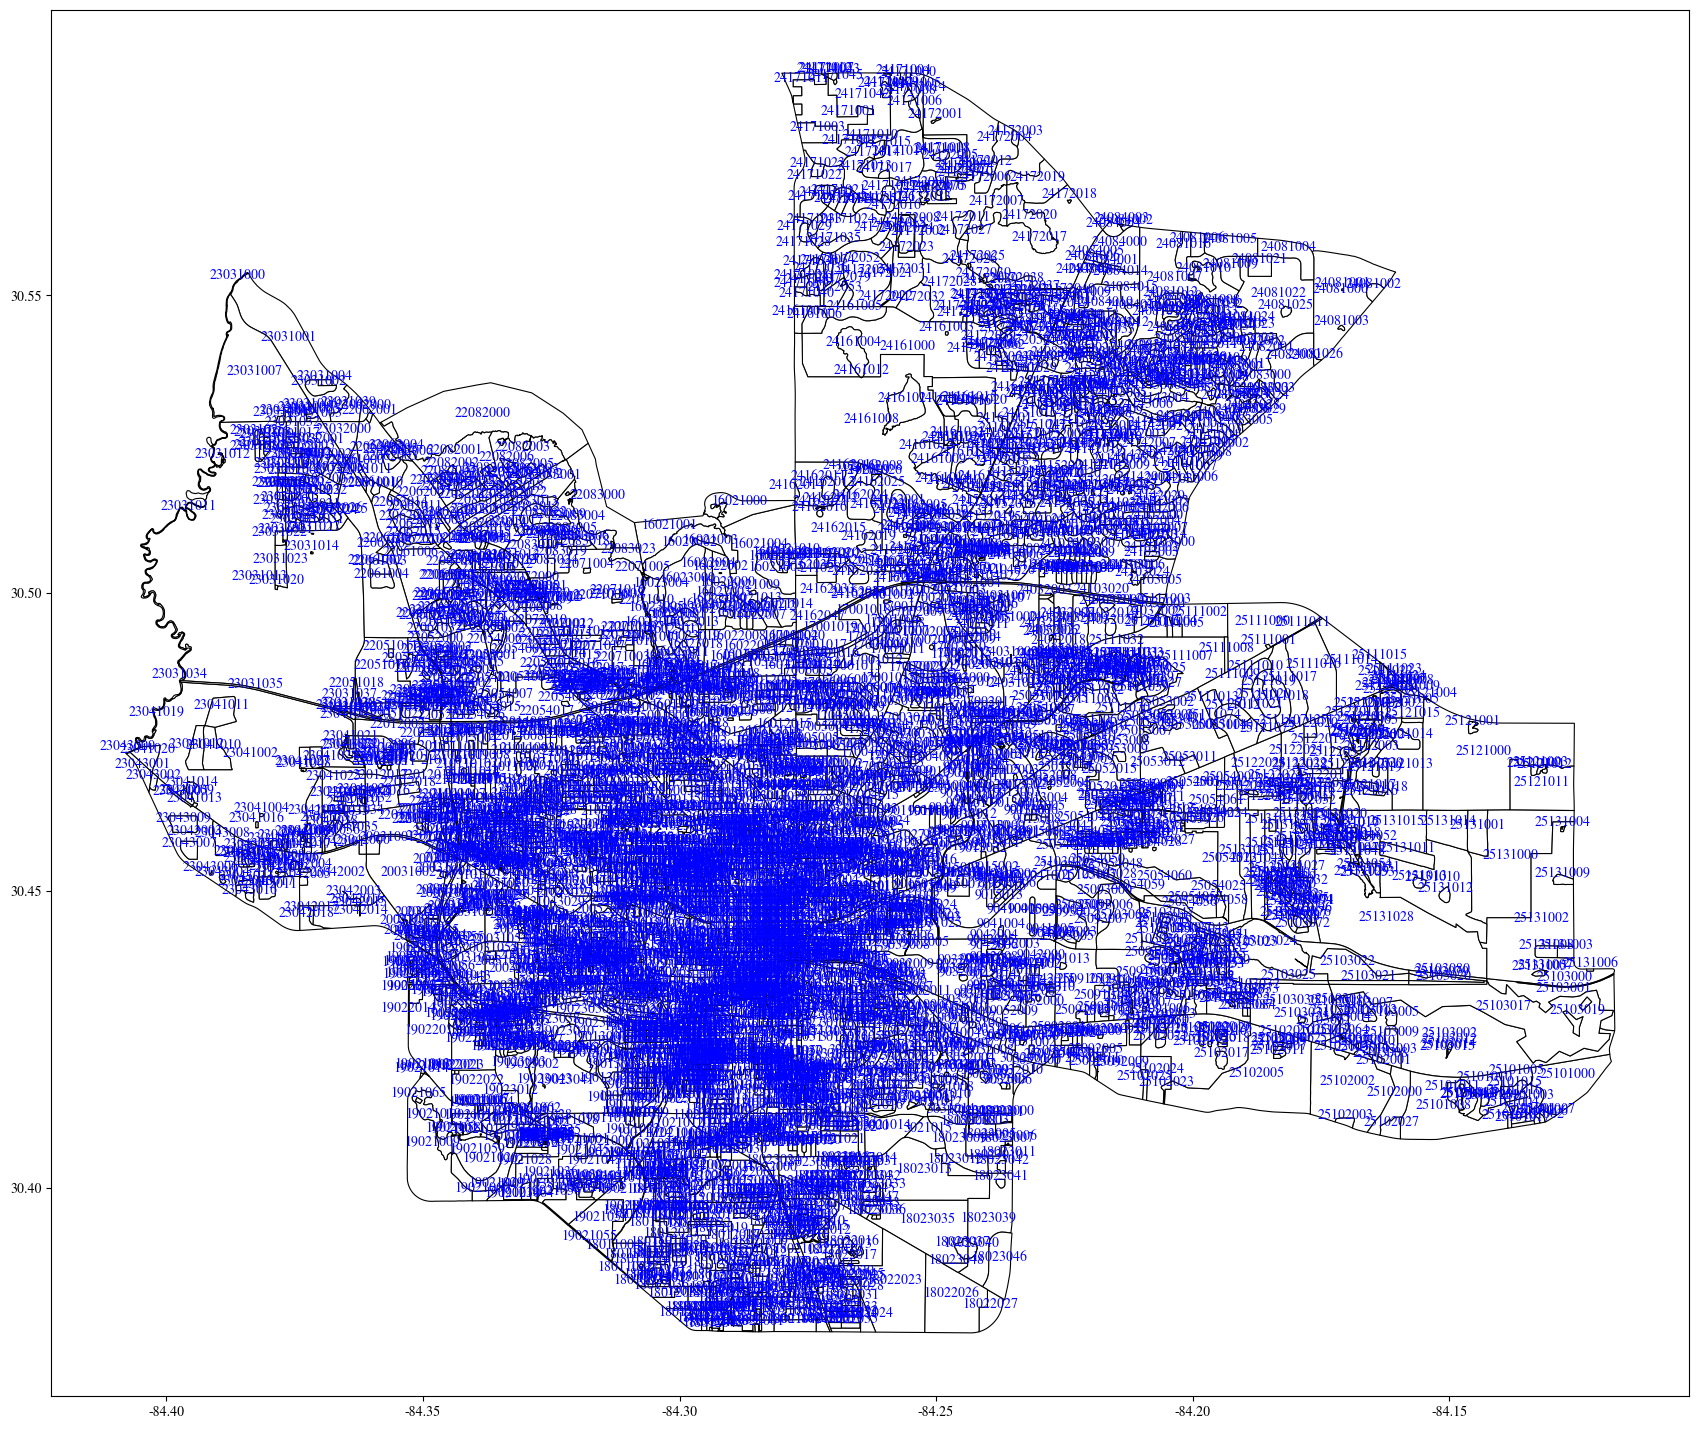

In [18]:
geodata = geopd.GeoDataFrame(boundary_block)
cmap = mpl.colors.ListedColormap(['cornsilk','yellow','gold','orange','red'])
cmap = LinearSegmentedColormap.from_list("",[(0,'#FFFFE0'),(0.35,'#FFFF00'),(0.75,'#FFA500'),(1,'#FF0000')],N=2)
fig = plt.figure(figsize = (30,18))
ax = fig.add_subplot(111)
geodata.plot(ax = ax,facecolor = 'white',edgecolor='black',lw=0.8,alpha=1,legend = False)
             
for i in range(geodata.shape[0]):
     ax.text(geodata.loc[i,'centroid'].x,geodata.loc[i,'centroid'].y,geodata.loc[i,'blockID'],
             fontsize=10, color="blue", ha="center", va="bottom")

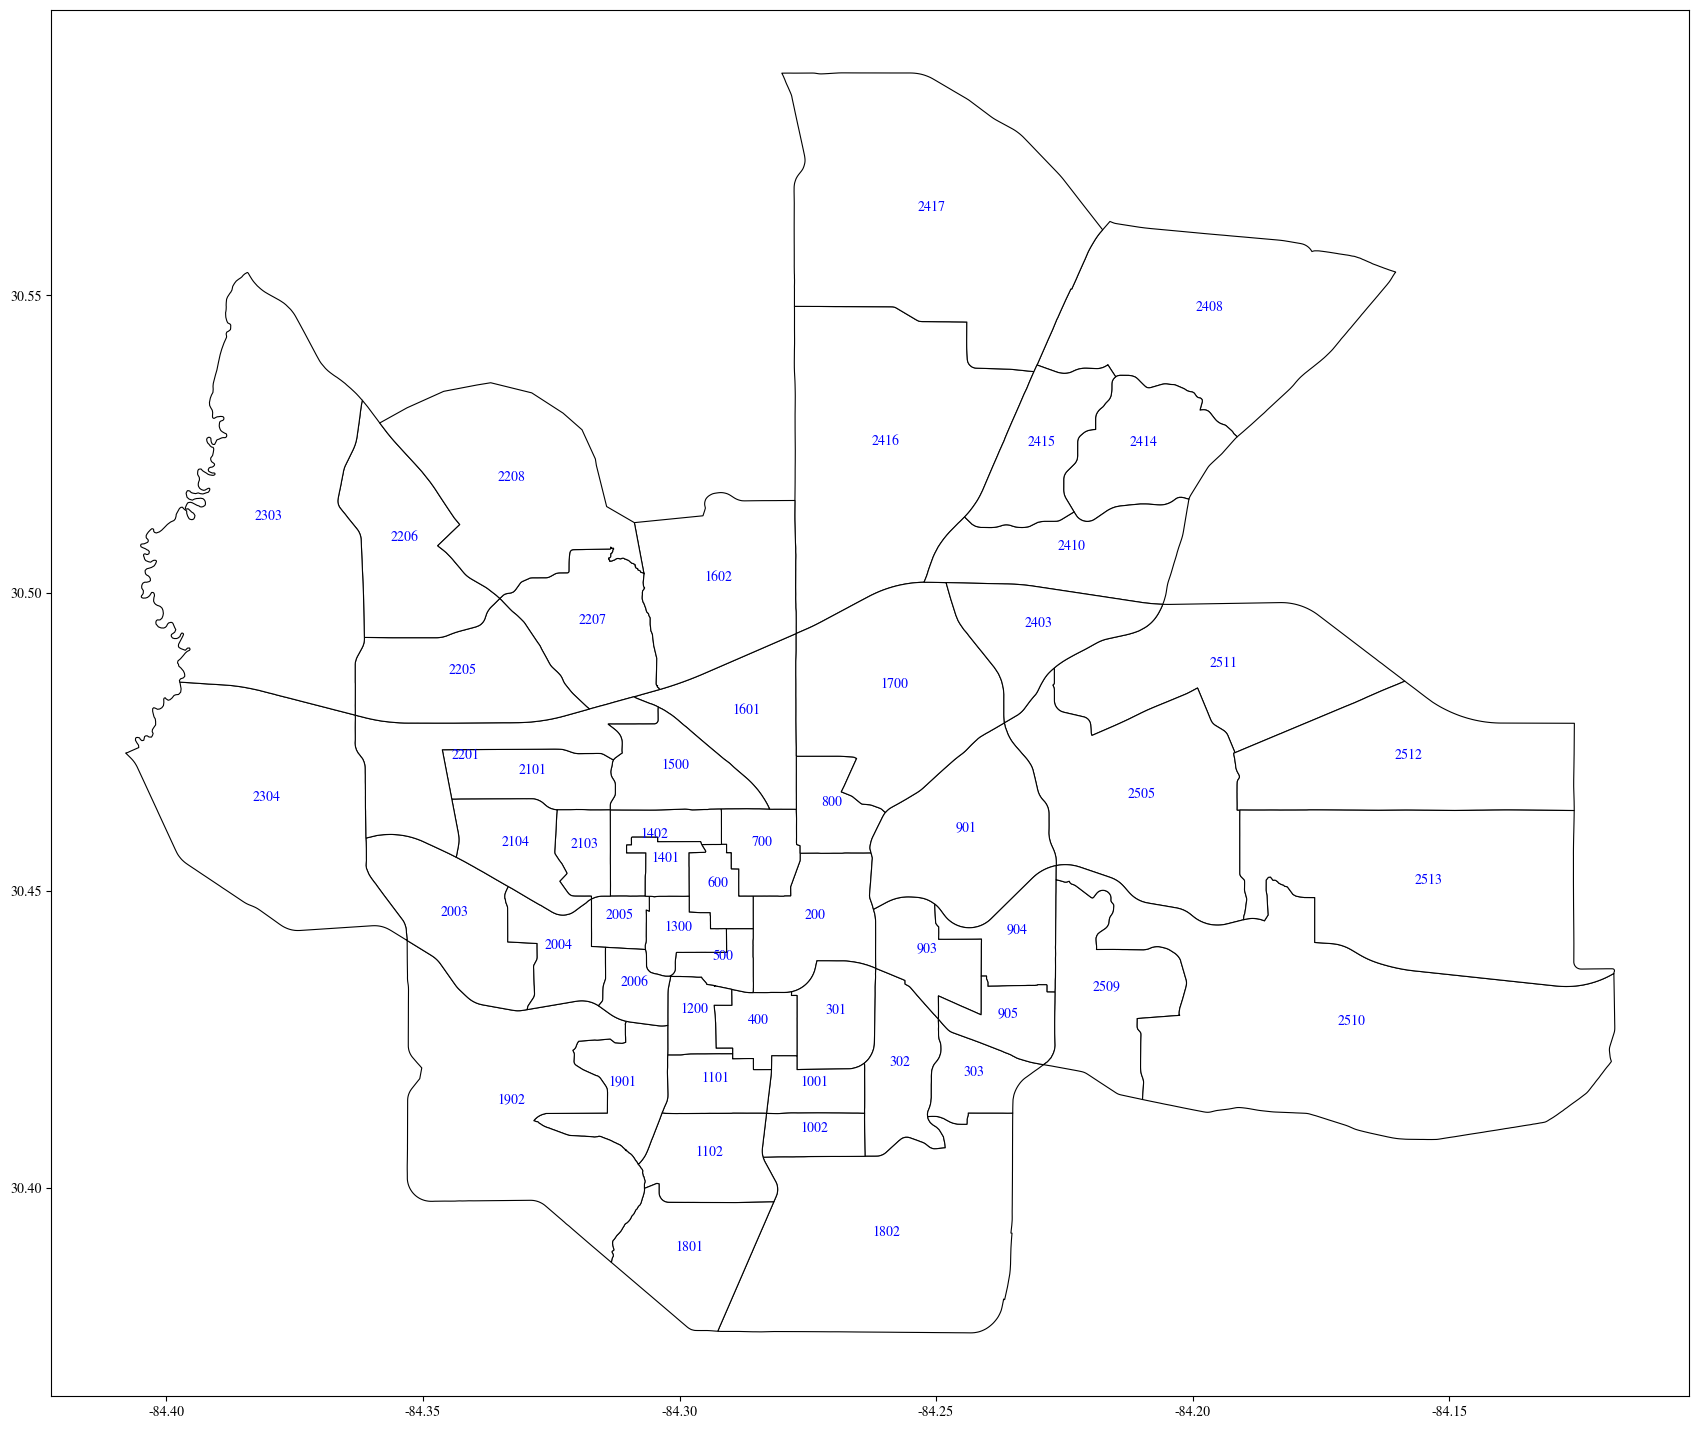

In [19]:
geodata = geopd.GeoDataFrame(boundary_tract)
cmap = mpl.colors.ListedColormap(['cornsilk','yellow','gold','orange','red'])
cmap = LinearSegmentedColormap.from_list("",[(0,'#FFFFE0'),(0.35,'#FFFF00'),(0.75,'#FFA500'),(1,'#FF0000')],N=2)
fig = plt.figure(figsize = (30,18))
ax = fig.add_subplot(111)
geodata.plot(ax = ax,facecolor = 'white',edgecolor='black',lw=0.8,alpha=1,legend = False)
             
for i in range(geodata.shape[0]):
     ax.text(geodata.loc[i,'centroid'].x,geodata.loc[i,'centroid'].y,geodata.loc[i,'tractID'],
             fontsize=10, color="blue", ha="center", va="bottom")

In [20]:
df1 = df[['BADGE','district']].drop_duplicates()
df1 = df1.dropna()
df1.index = range(df1.shape[0])
df1.columns = ['badge','location']
df1 = geopd.GeoDataFrame(df1, geometry="location", crs="EPSG:4326")


In [21]:
blocks = boundary_block[["tractID", "blockID", "geometry"]].copy()
df1_matched = geopd.sjoin(
    df1,
    blocks,
    how="left",
    predicate="within",
)
# sjoin 会多一列 index_right（右表行号）；不需要可删
df1_matched = df1_matched.drop(columns=["index_right"], errors="ignore")

In [22]:
df1_matched["location"] = df1_matched["location"].apply(lambda g: g.wkt)
df1_matched = df1_matched.dropna()
df1_matched.index = range(df1_matched.shape[0])
df1_matched['tractID'] = df1_matched['tractID'].astype(str)
df1_matched['blockID'] = df1_matched['blockID'].astype(str)

In [26]:
df1_matched.to_csv('../../Data/household_data/badge_location.csv',index=False)

# Tallahasee Census

In [29]:
tal_census = pd.read_csv("../../Data/origin_data/tal_demographic_sta_2018_tract.csv")
tal_census.head()

,pop_total,sex_total,sex_male,sex_female,age_median,households,race_total,race_white,race_black,race_native,race_asian,inc_total_pop,inc_no_pop,inc_with_pop,inc_pop_10k,inc_pop_1k_15k,inc_pop_15k_25k,inc_pop_25k_35k,inc_pop_35k_50k,inc_pop_50k_65k,inc_pop_65k_75k,inc_pop_75k,inc_median_ind,travel_total_to_work,travel_driving_to_work,travel_pt_to_work,travel_taxi_to_work,travel_cycle_to_work,travel_walk_to_work,travel_work_from_home,edu_total_pop,bachelor_male_25_34,master_phd_male_25_34,bachelor_male_35_44,master_phd_male_35_44,bachelor_male_45_64,master_phd_male_45_64,bachelor_male_65_over,master_phd_male_65_over,bachelor_female_25_34,master_phd_female_25_34,bachelor_female_35_44,master_phd_female_35_44,bachelor_female_45_64,master_phd_female_45_64,bachelor_female_65_over,master_phd_female_65_over,edu_total,edu_bachelor,edu_master,edu_phd,inc_median_household,inc_per_capita,employment_total_labor,employment_employed,employment_unemployed,housing_units_total,housing_units_occupied,housing_units_vacant,rent_median,property_value_total,property_value_median,vehicle_total_imputed,year,state,state_fips,county_fips,tract_fips,full_ct_fips
0,2301,2301,1051,1250,29.7,1248,2301,1451,741,0,34,2058,235,1823,362,99,229,408,429,162,55,79,28998,1359,1181,29,0,0,101,48,2046,90,85,53,7,14,8,26,28,86,103,16,42,61,7,54,7,1621,400,176,65,40273,26214,2058,1440,618,1394,1248,146,1027,191,145200,1359,2018,FL,12,73,903,12073000903
1,3549,3549,1613,1936,32.9,1883,3549,2322,915,0,146,3090,128,2962,356,183,339,651,655,389,136,253,34409,2302,2062,0,0,33,91,69,3090,120,82,73,35,80,48,27,48,256,165,50,89,98,88,16,42,2688,720,388,81,46715,32549,3090,2389,701,2077,1883,194,1000,840,144000,2302,2018,FL,12,73,904,12073000904
2,3109,3109,1533,1576,28.8,1461,3109,1745,1101,38,103,2743,253,2490,272,259,339,384,679,279,70,208,32449,2037,1702,101,0,0,100,106,2712,152,72,63,0,14,44,8,31,225,88,38,35,24,66,24,11,2114,548,280,37,51052,29647,2734,2141,593,1838,1461,377,1101,311,144900,2037,2018,FL,12,73,905,12073000905
3,1506,1506,627,879,33.8,739,1506,354,943,0,140,1445,224,1221,423,288,264,131,79,18,13,5,12974,604,469,0,0,107,28,0,1420,0,5,0,0,10,0,0,0,14,20,28,2,37,8,15,35,951,104,70,0,14504,13023,1445,723,722,1062,739,323,895,240,89700,604,2018,FL,12,73,1401,12073001401
4,5352,5352,2486,2866,22.4,1914,5352,1507,3227,61,401,4732,1222,3510,1516,588,580,521,204,55,46,0,12060,2364,1881,209,0,22,79,82,4639,145,50,27,0,0,0,0,0,205,67,24,39,12,0,0,0,1453,413,149,7,18598,10503,4696,2961,1735,2219,1914,305,1009,159,87000,2364,2018,FL,12,73,1402,12073001402


In [31]:
import numpy as np

tal_census_selected = tal_census[
    [
        "pop_total",
        "households",
        "age_median",
        "sex_male",
        "sex_total",
        "race_white",
        "race_total",
        "inc_median_ind",
        "inc_median_household",
        "inc_per_capita",
        "inc_pop_10k",
        "inc_total_pop",
        "travel_work_from_home",
        "travel_total_to_work",
        "edu_bachelor",
        "edu_master",
        "edu_phd",
        "rent_median",
        "property_value_median",
        "tract_fips",
        "full_ct_fips",
    ]
].copy()

# 性别比例：男性 / 总人数
tal_census_selected["male_ratio"] = (
    tal_census_selected["sex_male"]
    / tal_census_selected["sex_total"].replace(0, np.nan)
)

# 种族比例：白人 / 总人数
tal_census_selected["white_ratio"] = (
    tal_census_selected["race_white"]
    / tal_census_selected["race_total"].replace(0, np.nan)
)

# 年收入低于 10k 的人口比例
tal_census_selected["low_income_ratio"] = (
    tal_census_selected["inc_pop_10k"]
    / tal_census_selected["inc_total_pop"].replace(0, np.nan)
)

# 居家办公人数比例
tal_census_selected["work_from_home_ratio"] = (
    tal_census_selected["travel_work_from_home"]
    / tal_census_selected["travel_total_to_work"].replace(0, np.nan)
)

# 本科及以上人数比例
tal_census_selected["bachelor_or_above_ratio"] = (
    tal_census_selected["edu_bachelor"]
    + tal_census_selected["edu_master"]
    + tal_census_selected["edu_phd"]
) / tal_census_selected["pop_total"].replace(0, np.nan)

# 最终保留字段
tal_census_selected = tal_census_selected[
    [
        "pop_total",
        "households",
        "age_median",
        "male_ratio",
        "white_ratio",
        "inc_median_ind",
        "inc_median_household",
        "inc_per_capita",
        "low_income_ratio",
        "work_from_home_ratio",
        "bachelor_or_above_ratio",
        "rent_median",
        "property_value_median",
        "tract_fips",
        "full_ct_fips",
    ]
].copy()

In [33]:
tal_census_selected.to_csv('../../Data/census_data/tal_census.csv',index=False)

In [34]:
geo = geopd.GeoDataFrame(boundary_tract).copy()
cols = ["households", "inc_median_household", "full_ct_fips"]  # 加合并键
geo_data = geo.merge(
    tal_census_selected[cols],
    left_on="geoid",
    right_on="full_ct_fips",
    how="left",
)

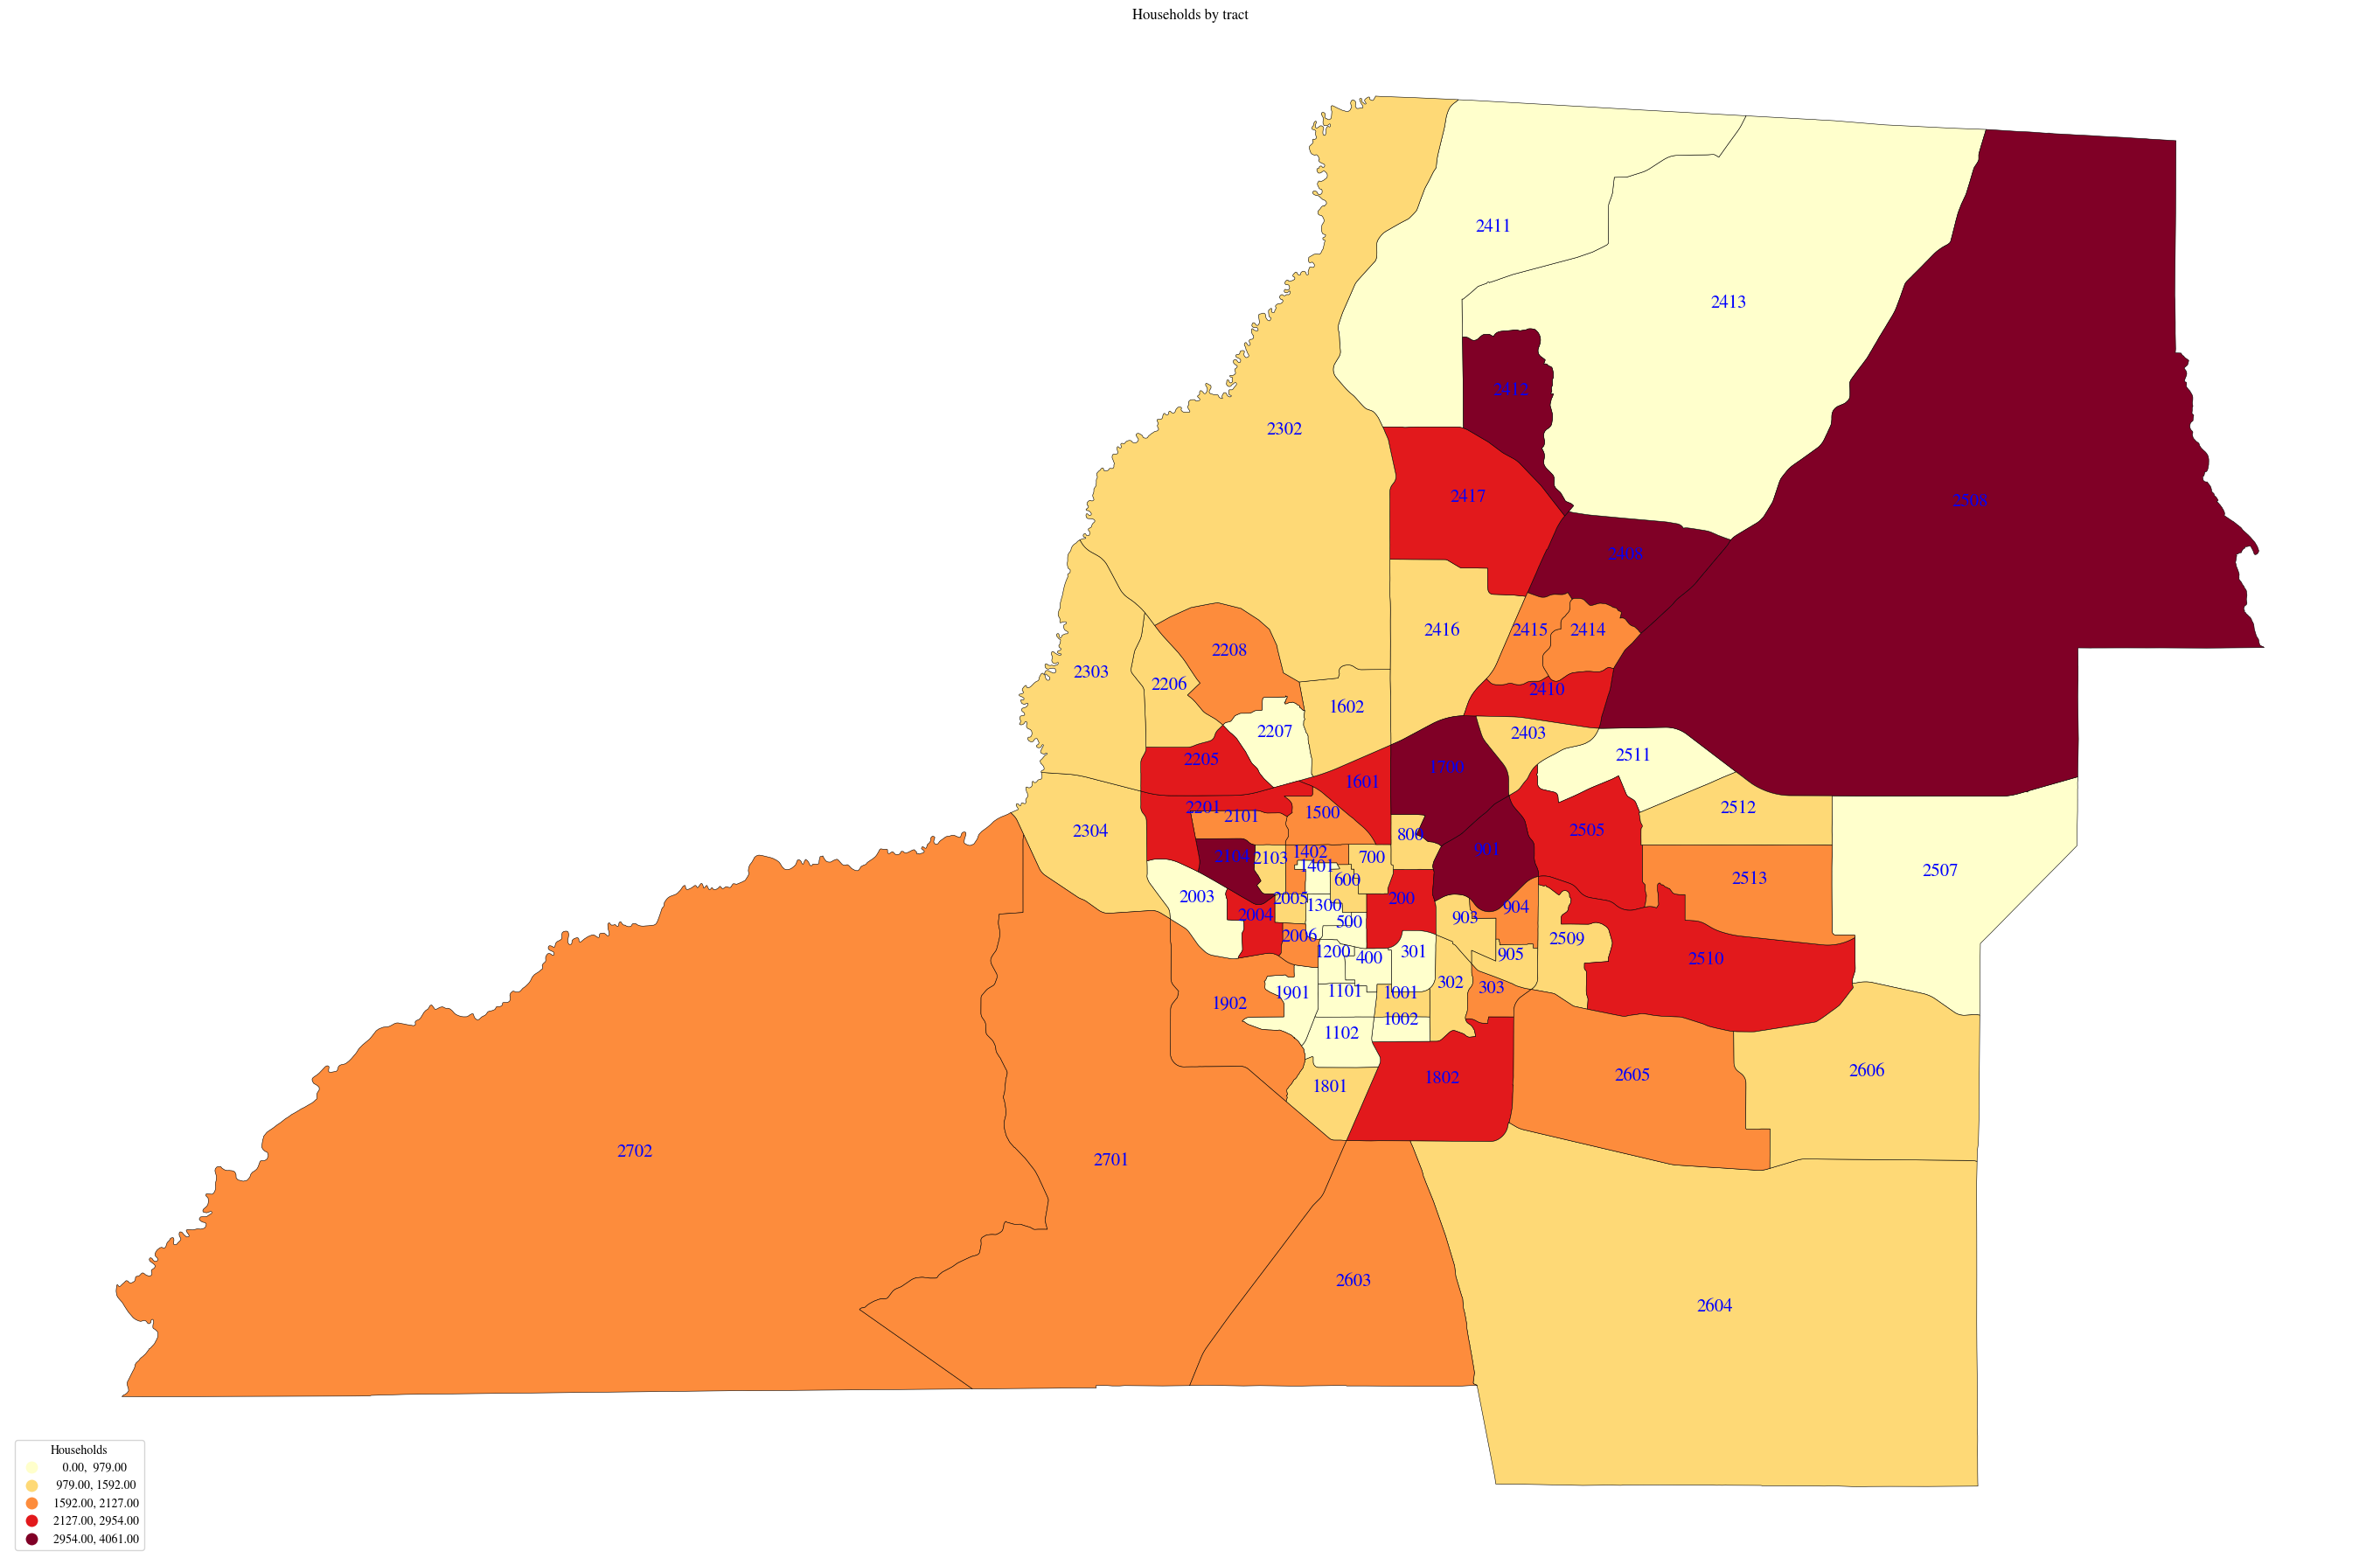

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(30, 18))
geo_data.plot(
    ax=ax,
    column="households",
    scheme="naturalbreaks",   # 或 "quantiles"、"equal_interval"；数据少可去掉 scheme
    k=5,
    cmap="YlOrRd",
    legend=True,
    legend_kwds={"title": "Households", "loc": "lower left"},
    edgecolor="black",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
for _, row in geo_data.iterrows():
    c = row["centroid"]
    if hasattr(c, "x"):
        ax.text(
            c.x, c.y, str(row["tractID"]),
            fontsize=15, color="blue", ha="center", va="bottom",
        )
ax.set_title("Households by tract")
ax.set_axis_off()
plt.tight_layout()
plt.show()

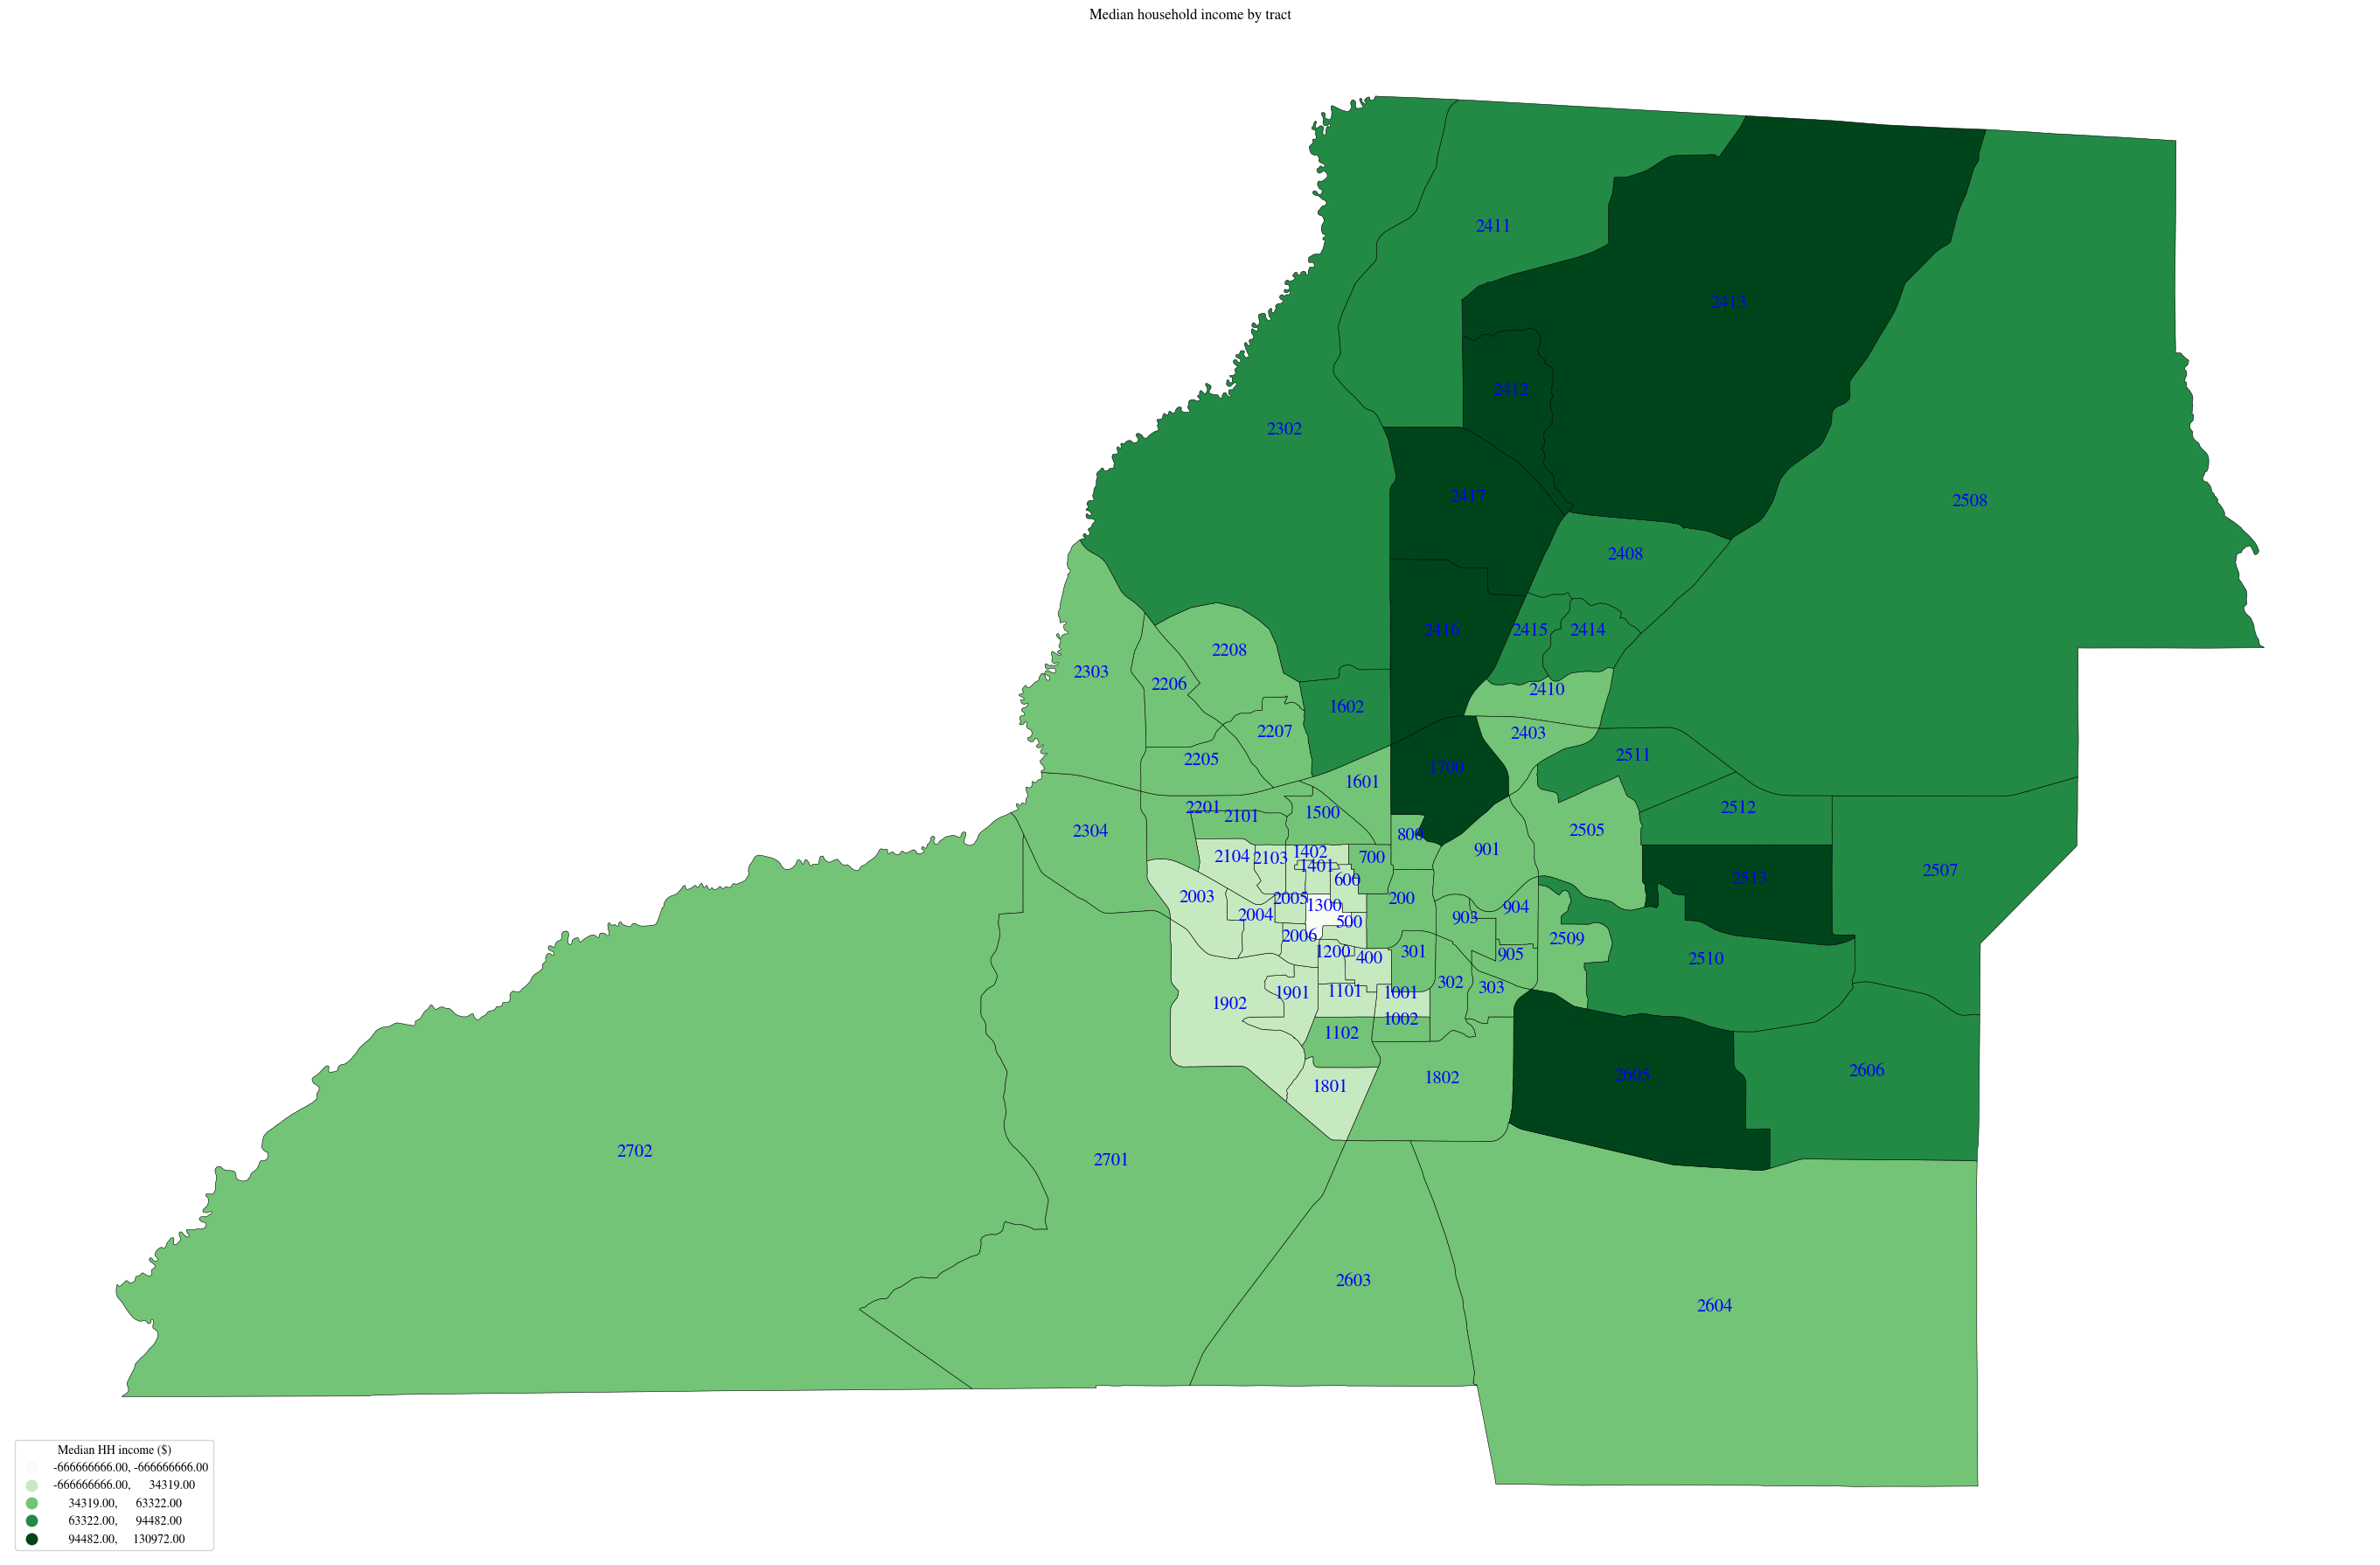

In [38]:
fig, ax = plt.subplots(1, 1, figsize=(30, 18))
geo_data.plot(
    ax=ax,
    column="inc_median_household",
    scheme="naturalbreaks",
    k=5,
    cmap="Greens",           # 可改成 RdYlGn 等
    legend=True,
    legend_kwds={"title": "Median HH income ($)", "loc": "lower left"},
    edgecolor="black",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
for _, row in geo_data.iterrows():
    c = row["centroid"]
    if hasattr(c, "x"):
        ax.text(
            c.x, c.y, str(row["tractID"]),
            fontsize=15, color="blue", ha="center", va="bottom",
        )
ax.set_title("Median household income by tract")
ax.set_axis_off()
plt.tight_layout()
plt.show()